# Proyecto Oráculo · Notebook de búsqueda (ADAG1, Grupo 1)

Lenuard · Análisis y Diseño de Algoritmos 2026-B · primera entrega

Este notebook documenta **cómo se obtuvo** la configuración de `entrega.json`:

1. **Diagnóstico por trazas**: cada opción se mide sola y las trazas de fallo (`violo`) dicen qué familia rompe. Se conservan las `K` mejores por ranura, y el espacio pasa de 8⁵ = 32 768 a K⁵ configs.
2. **Búsqueda** en el espacio reducido con los algoritmos del enunciado: backtracking con poda (Alg. 1), Successive Halving (Alg. 2), descenso por coordenadas (Alg. 3) y reparto de presupuesto uniforme frente a adaptativo (Alg. 4). Cada uno tiene su propio contador de consultas con tope `B`.
3. **Selección**: la config de mayor precisión en el lote de búsqueda. Es la **mejor observada**, no un óptimo garantizado.
4. **Validación** con `oraculo.validar` sobre la partición de validación, que no se usó para buscar.
5. **Entrega**: `entrega.json` con esa misma config.

Necesita **GPU T4**: *Entorno de ejecución ▸ Cambiar tipo de entorno de ejecución ▸ T4 GPU*.

## 1 · Instalar y clonar el repo · *al terminar, reinicia el entorno de ejecución*

In [1]:
# bitsandbytes: checkpoints 4-bit. nltk/spacy/emoji/langdetect: los usa el
# verificador de open-instruct. Copia de la celda 1 del notebook del curso, pero
# clonando el fork del grupo en vez de bajar los .py sueltos.
!pip install -q -U "bitsandbytes>=0.46.1" transformers accelerate \
                   nltk spacy emoji langdetect immutabledict
!python -m spacy download en_core_web_sm -q

%cd /content
# oraculo.py busca los verificadores en /content/open-instruct.
!test -d open-instruct || git clone -q https://github.com/allenai/open-instruct
# El repo del grupo trae oraculo.py, ayudas.py, datos_visibles.json, busqueda/ y entrega.json.
!test -d ADA-2026-2-GP01 && git -C ADA-2026-2-GP01 pull -q || git clone -q https://github.com/Lenuard/ADA-2026-2-GP01

# Los datos de nltk se bajan a mano: su downloader rechaza el proxy de Colab.
import io
import urllib.request
import zipfile

NLTK_DATA = "https://raw.githubusercontent.com/nltk/nltk_data/gh-pages/packages"
PAQUETES = [
    ("tokenizers", "punkt"),
    ("tokenizers", "punkt_tab"),
    ("taggers", "averaged_perceptron_tagger"),
    ("taggers", "averaged_perceptron_tagger_eng"),
]
for carpeta, nombre in PAQUETES:
    with urllib.request.urlopen(f"{NLTK_DATA}/{carpeta}/{nombre}.zip") as resp:
        zipfile.ZipFile(io.BytesIO(resp.read())).extractall(f"/root/nltk_data/{carpeta}")

print("LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2")

✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
/content
LISTO  →  Entorno de ejecución ▸ Reiniciar sesión, y sigue en la celda 2


## 2 · Modelo y oráculo

El mismo modelo y los mismos parámetros de lote que el notebook del curso. Si Colab se desconecta, el caché en Drive conserva las generaciones ya pagadas (descomentar las líneas).

In [2]:
%cd /content/ADA-2026-2-GP01
import sys
sys.path.insert(0, "/content/ADA-2026-2-GP01")

from ayudas import cargar_modelo

MODELO = "qwen17b"
modelo = cargar_modelo(MODELO)

/content/ADA-2026-2-GP01
cargando qwen17b → Qwen/Qwen3-1.7B


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Qwen/Qwen3-1.7B  VRAM: 3.44 GB


In [3]:
from google.colab import drive
drive.mount("/content/drive")

from oraculo import Oraculo
from ayudas import cargar_datos, dividir, curva, entrega

datos = cargar_datos()
busqueda, validacion = dividir(datos)
#oraculo = Oraculo(modelo, busqueda, validacion, lote=16, presupuesto=32_000_000)
oraculo = Oraculo(modelo, busqueda, validacion, cache="/content/drive/MyDrive/oraculo_cache.json", lote=16, presupuesto=32_000_000)

Mounted at /content/drive
450 instancias, 2.3 restricciones por instancia
búsqueda: 100 inst, 2.5 restr/inst
validación: 87 inst, 2.4 restr/inst
(263 instancias descartadas: no medían nada — ver `dividir`)
modo pensamiento: apagado
caché: 2050 respuestas recuperadas


## 3 · Parámetros

Cada consulta es un par (config, instancia), es decir **una generación del LLM en la T4**. Por eso el costo se cuenta en consultas.

| Parámetro | Valor | Por qué |
|---|---|---|
| `K` | 2 | Opciones conservadas por ranura. Con 2, \|C'\| = 2⁵ = 32: recorrer todo C' con 100 instancias cuesta 3 200 consultas, frente a 3 276 800 en el espacio completo. |
| `N_DIAG` | 50 | Instancias del diagnóstico. Son (1 + 5·8)·50 = 2 050 consultas; con 50, una opción que rompe una familia frecuente ya se separa de la base. |
| `INST` | las 100 de búsqueda | Lote con el que se comparan las configs. El puntaje es todo-o-nada; con menos instancias muchas configs empatan en 0. |
| `N0` | 3 | Successive Halving: R = log₂32 = 5 rondas con 3, 6, 12, 24 y 48 instancias, y costo nominal 32·3·5 = 480. |
| `B` | 3 200 | Tope de consultas **por algoritmo** (= \|C'\|·100, el costo de la fuerza bruta en C'). Ninguno puede gastar más. |
| `MAX_ITER` | 10 | Tope del descenso por coordenadas, que además para cuando una iteración no cambia nada. |
| `SEMILLA` | 1 | Semilla de generación; en temperatura 0.0 el decode es greedy. |

La temperatura queda fija en **0.0** en esta entrega.

In [4]:
GRUPO = "G01"
SEMANA = 8
SEMILLA = 1
K = 2
N_DIAG = 50
INST = busqueda          # las 100 instancias de búsqueda
N0 = 3
B = 3200
MAX_ITER = 10
BS_REPARTO = [160, 480, 960, 1600]   # presupuestos para comparar repartos (Alg. 4)

## 4 · (a) Diagnóstico por trazas → espacio reducido

Primero se mide la **config vacía** (sin ninguna ranura, solo la petición) y después cada una de las 40 opciones **sola**. Para cada opción la tabla muestra:

- `precision` y `delta` frente a la base;
- `familias_de_mas`: las familias `violo` que aparecen más veces que en la base, es decir, lo que esa opción rompe;
- `conservada` y `motivo`: la decisión que se tomó.

In [5]:
import pandas as pd
from collections import Counter

from busqueda import (
    OraculoContado, backtracking, comparar_repartos, descenso_coordenadas,
    diagnosticar, espacio_reducido, ordenar, successive_halving,
    validar_config, validar_entrega,
)

pd.set_option("display.max_colwidth", 120)

INST_DIAG = INST[:N_DIAG]
opciones, tabla = diagnosticar(oraculo, INST_DIAG, k=K, semilla=SEMILLA)
df_diag = pd.DataFrame(tabla)
df_diag["precision"] = df_diag["precision"].map("{:.1%}".format)
df_diag["delta"] = df_diag["delta"].map("{:+.1%}".format)
df_diag[["ranura", "opcion", "precision", "delta", "conservada", "motivo"]]

,ranura,opcion,precision,delta,conservada,motivo
0,rol,0,12.0%,+0.0%,False,"descartada: precisión 12.0% < corte 16.0%; rompe punctuation:punctuation_dot (+1), keywords:existence (+1), paragrap..."
1,rol,1,14.0%,+2.0%,False,"descartada: precisión 14.0% < corte 16.0%; rompe punctuation:punctuation_dot (+1), length_constraints:number_words (..."
2,rol,2,20.0%,+8.0%,True,"conservada; familias de más: copy:copy (+1), length_constraints:number_paragraphs (+1), paragraphs:paragraphs2 (+1)"
3,rol,3,16.0%,+4.0%,False,"descartada por desempate (más fallos de más); rompe change_case:english_capital (+2), punctuation:punctuation_dot (+..."
4,rol,4,14.0%,+2.0%,False,"descartada: precisión 14.0% < corte 16.0%; rompe startend:quotation (+1), keywords:keyword_specific_position (+1), c..."
5,rol,5,16.0%,+4.0%,True,"conservada; familias de más: punctuation:punctuation_dot (+1), keywords:keyword_specific_position (+1), last_word:la..."
6,rol,6,14.0%,+2.0%,False,"descartada: precisión 14.0% < corte 16.0%; rompe punctuation:punctuation_dot (+2), keywords:keyword_specific_positio..."
7,rol,7,14.0%,+2.0%,False,"descartada: precisión 14.0% < corte 16.0%; rompe punctuation:punctuation_dot (+1), keywords:existence (+1), change_c..."
8,estrategia,0,12.0%,+0.0%,False,"descartada: precisión 12.0% < corte 18.0%; rompe punctuation:punctuation_dot (+2), length_constraints:number_words (..."
9,estrategia,1,10.0%,-2.0%,False,"descartada: precisión 10.0% < corte 18.0%; rompe paragraphs:paragraphs2 (+2), punctuation:punctuation_dot (+1), keyw..."


In [6]:
base = oraculo.evaluar({"temperatura": 0.0}, INST_DIAG, semilla=SEMILLA)
print(f"config vacía: {base.precision:.1%} en {base.n} instancias")
print("familias que ya fallan sin ninguna ranura:",
      Counter(t["violo"] for t in base.trazas).most_common(5))
print()
for ranura, ops in opciones.items():
    descartadas = [f["opcion"] for f in tabla if f["ranura"] == ranura and not f["conservada"]]
    print(f"{ranura:10}  conservadas {ops}   descartadas {descartadas}")

C_RED = espacio_reducido(opciones)
print(f"\nespacio: 32768 → {len(C_RED)} configs")

config vacía: 12.0% en 50 instancias
familias que ya fallan sin ninguna ranura: [('last_word:last_word_sent', 5), ('keywords:start_end', 3), ('paragraphs:paragraphs', 2), ('startend:quotation', 2), ('keywords:word_once', 2)]

rol         conservadas [2, 5]   descartadas [0, 1, 3, 4, 6, 7]
estrategia  conservadas [6, 3]   descartadas [0, 1, 2, 4, 5, 7]
formato     conservadas [0, 2]   descartadas [1, 3, 4, 5, 6, 7]
estilo      conservadas [0, 6]   descartadas [1, 2, 3, 4, 5, 7]
cierre      conservadas [3, 6]   descartadas [0, 1, 2, 4, 5, 7]

espacio: 32768 → 32 configs


**Qué decisiones salen de las trazas**

- **Base.** La config vacía acierta el 12 % de las 50 instancias. Las familias que ya fallan sin ninguna ranura (`last_word:last_word_sent`, `keywords:start_end`, `paragraphs:paragraphs`, …) son límites del modelo, no de la configuración. Ninguna opción del catálogo las puede arreglar quitándose.
- **Daño claro, descartado con confianza.** Las opciones que agregan estructura o texto obligatorio bajan entre 4 y 8 puntos frente a la base:
  - `formato` 4 (al menos cuatro párrafos) y 5 (línea de resumen en negrita) caen a 4 %, y 7 (párrafos numerados) a 8 %;
  - `cierre` 7 (línea "Next:") cae a 4 %, y 4 (P.S.) y 5 (pregunta final) a 8 %.

  Las familias de más que aparecen (`keywords:existence`, `punctuation:punctuation_dot`, `startend:quotation`, `length_constraints:number_words`) son justo las que castigan el texto añadido.
- **Mejoras sobre la base.** `rol` 2 y `formato` 0 suben 8 puntos; `estrategia` 3, 6 y 7 y `estilo` 0 suben 6.
- **Decisión.** C' = {rol 2, 5} × {estrategia 6, 3} × {formato 0, 2} × {estilo 0, 6} × {cierre 3, 6}, es decir 32 configs. La fuerza bruta en C' cuesta 3 200 consultas en vez de 3 276 800, y ningún algoritmo de la sección (b) vuelve a evaluar las 30 opciones descartadas.
- **Límite de esta evidencia.** Con 50 instancias, una instancia son 2 puntos, y el error estándar ronda ±5 puntos. Las "familias de más" son de +1 o +2: señal débil por familia. El diagnóstico es fiable para las opciones muy dañinas (`formato` 4/5/7, `cierre` 4/5/7). Para el resto, muchas diferencias de 2–4 puntos están dentro del ruido. Varias opciones quedaron fuera por desempate (`rol` 3, `estrategia` 7, `estilo` 2 y 5) o por una sola instancia. Ese es el riesgo principal de la búsqueda: una opción buena descartada aquí ya no la ve ningún algoritmo.

## 5 · (b) Los cuatro algoritmos sobre C'

Cada algoritmo usa su propio `OraculoContado(oraculo, B)`, que cuenta las consultas **nuevas para ese algoritmo**. El caché del oráculo es compartido, así que en la GPU solo se paga la unión, pero la comparación entre algoritmos es justa.

In [7]:
cont_bt = OraculoContado(oraculo, B, "backtracking")
r_bt = backtracking(cont_bt, opciones, INST, semilla=SEMILLA)
print("Alg. 1 backtracking:", r_bt["config"], f"{r_bt['precision']:.1%}",
      f"| nodos {r_bt['nodos']}, podas {r_bt['podas']}, consultas {cont_bt.consultas}/{B}")

evaluando:   0%|          | 0/50 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/50 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/100 [00:00<?, ?inst/s]

Alg. 1 backtracking: {'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0} 15.0% | nodos 10, podas 5, consultas 1000/3200


In [8]:
cont_sh = OraculoContado(oraculo, B, "successive_halving")
r_sh = successive_halving(cont_sh, C_RED, INST, N0, semilla=SEMILLA)
print("Alg. 2 Successive Halving:", r_sh["config"], f"{r_sh['precision']:.1%} (en su última ronda)")
print(f"  rondas {r_sh['rondas']}, consultas nominales {r_sh['consultas_nominales']} "
      f"= fórmula |C|·n0·log2|C| = {r_sh['consultas_formula']:.0f}; reales {cont_sh.consultas}")
pd.DataFrame(r_sh["historia"])

evaluando:   0%|          | 0/3 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/3 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/3 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/3 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/3 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/3 [00:00<?, ?inst/s]

... (46 outputs left out)

evaluando:   0%|          | 0/12 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/24 [00:00<?, ?inst/s]

Alg. 2 Successive Halving: {'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0} 14.6% (en su última ronda)
  rondas 5, consultas nominales 480 = fórmula |C|·n0·log2|C| = 480; reales 288


,ronda,n,evaluadas
0,0,3,32
1,1,6,16
2,2,12,8
3,3,24,4
4,4,48,2


In [9]:
cont_cd = OraculoContado(oraculo, B, "coordenadas")
r_cd = descenso_coordenadas(cont_cd, opciones, INST, max_iter=MAX_ITER, semilla=SEMILLA)
print("Alg. 3 descenso por coordenadas:", r_cd["config"], f"{r_cd['precision']:.1%}",
      f"| iteraciones {r_cd['iteraciones']}, convergió {r_cd['convergio']}, consultas {cont_cd.consultas}/{B}")

evaluando:   0%|          | 0/76 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/97 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/97 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/97 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/97 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/97 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/97 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/97 [00:00<?, ?inst/s]

Alg. 3 descenso por coordenadas: {'rol': 5, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0} 17.0% | iteraciones 2, convergió True, consultas 900/3200


In [10]:
# Alg. 4: mismo B para los dos repartos. La ganadora de cada uno se mide sobre
# las 100 instancias (sin cobrar) para ver cuál elige mejor.
filas_rep = comparar_repartos(oraculo, C_RED, INST, BS_REPARTO, semilla=SEMILLA)
df_rep = pd.DataFrame(filas_rep)
df_rep

evaluando:   0%|          | 0/2 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/2 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/2 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/2 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/2 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/2 [00:00<?, ?inst/s]

... (63 outputs left out)

evaluando:   0%|          | 0/20 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/20 [00:00<?, ?inst/s]

evaluando:   0%|          | 0/20 [00:00<?, ?inst/s]

,B,metodo,config,precision_busqueda,precision_referencia,consultas
0,160,uniforme,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}",0.000000,0.12,160
1,160,adaptativo,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}",0.062500,0.12,96
2,480,uniforme,"{'rol': 2, 'estrategia': 3, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}",0.200000,0.14,480
3,480,adaptativo,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",0.145833,0.15,288
4,960,uniforme,"{'rol': 2, 'estrategia': 3, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}",0.166667,0.14,960
5,960,adaptativo,"{'rol': 2, 'estrategia': 3, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}",0.135417,0.14,576
6,1600,uniforme,"{'rol': 2, 'estrategia': 3, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}",0.180000,0.14,1600
7,1600,adaptativo,"{'rol': 2, 'estrategia': 3, 'formato': 0, 'estilo': 0, 'cierre': 3, 'temperatura': 0.0}",0.135417,0.14,576


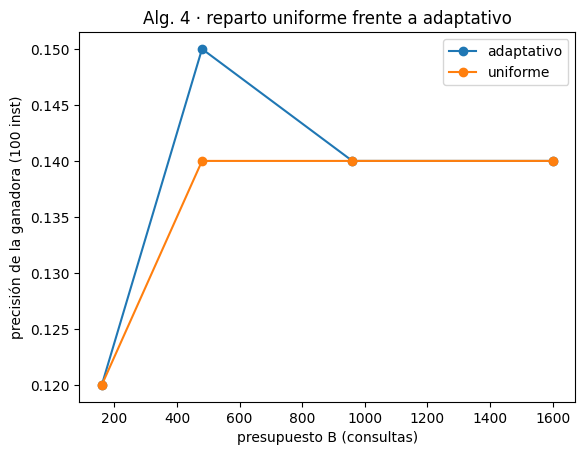

In [11]:
import matplotlib.pyplot as plt

for metodo, g in df_rep.groupby("metodo"):
    plt.plot(g["B"], g["precision_referencia"], marker="o", label=metodo)
plt.xlabel("presupuesto B (consultas)")
plt.ylabel("precisión de la ganadora (100 inst)")
plt.title("Alg. 4 · reparto uniforme frente a adaptativo")
plt.legend()
plt.show()

### Registro de todas las configs evaluadas

In [12]:
registro = cont_bt.registro + cont_sh.registro + cont_cd.registro
df_reg = pd.DataFrame(registro)
df_reg["config"] = df_reg["config"].map(lambda c: str(ordenar(c)))
df_reg["completa"] = df_reg["config"].map(lambda s: all(r in s for r in ("rol", "estrategia", "formato", "estilo", "cierre")))
df_reg.to_csv("registro_busqueda.csv", index=False)
print(f"{len(df_reg)} evaluaciones registradas (guardadas en registro_busqueda.csv)")
df_reg.sort_values("precision", ascending=False)

83 evaluaciones registradas (guardadas en registro_busqueda.csv)


,algoritmo,config,n,precision,completa
0,backtracking,"{'rol': 2, 'temperatura': 0.0}",100,0.18,False
76,coordenadas,"{'rol': 5, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",100,0.17,True
7,backtracking,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'temperatura': 0.0}",100,0.16,False
78,coordenadas,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",100,0.15,True
8,backtracking,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",100,0.15,True
...,...,...,...,...,...
51,successive_halving,"{'rol': 2, 'estrategia': 3, 'formato': 0, 'estilo': 0, 'cierre': 6, 'temperatura': 0.0}",6,0.00,True
55,successive_halving,"{'rol': 2, 'estrategia': 3, 'formato': 2, 'estilo': 0, 'cierre': 6, 'temperatura': 0.0}",6,0.00,True
56,successive_halving,"{'rol': 2, 'estrategia': 3, 'formato': 2, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",6,0.00,True
57,successive_halving,"{'rol': 2, 'estrategia': 3, 'formato': 2, 'estilo': 6, 'cierre': 6, 'temperatura': 0.0}",6,0.00,True


backtracking — 1000 consultas


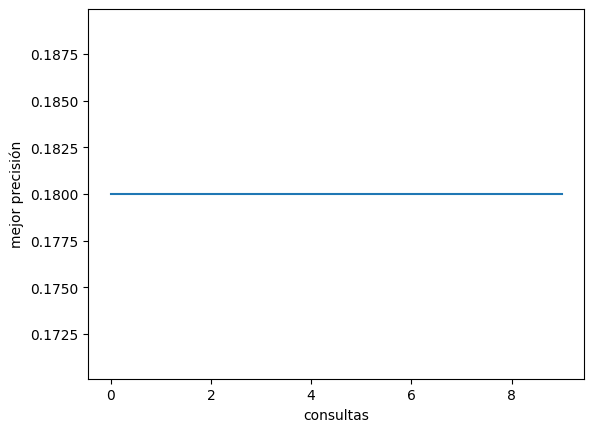

successive_halving — 288 consultas


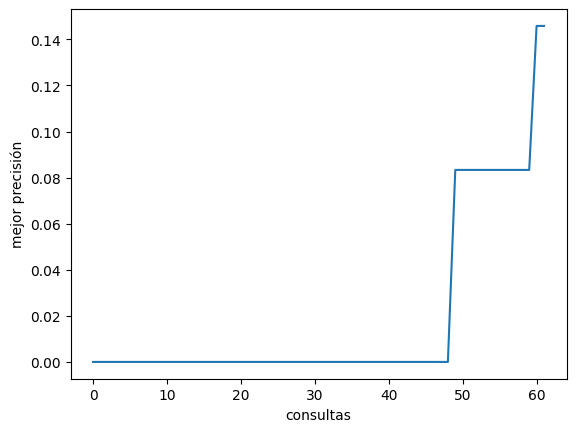

coordenadas — 900 consultas


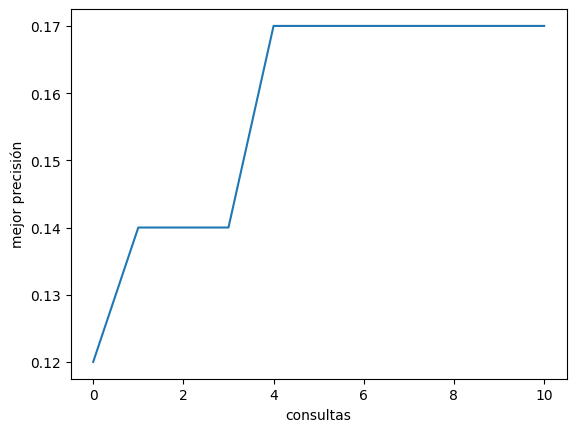

In [13]:
for cont in (cont_bt, cont_sh, cont_cd):
    print(cont.algoritmo, f"— {cont.consultas} consultas")
    curva(cont.historial)

### Qué se obtuvo con cada algoritmo

| Algoritmo | Config (rol, estrategia, formato, estilo, cierre) | Precisión (100 inst) | Consultas propias |
|---|---|---|---|
| 1 · Backtracking con poda | 2, 6, 0, 6, 3 | 15 % | 1 000 (10 nodos, 5 podas) |
| 2 · Successive Halving (n0 = 3) | 2, 6, 0, 6, 3 | 15 % (14,6 % en su última ronda de 48) | 288 reales; 480 nominales = \|C\|·n0·log₂\|C\| |
| 3 · Descenso por coordenadas | **5, 6, 0, 6, 3** | **17 %** | 900 (2 iteraciones, convergió) |

- **La cota del backtracking no es válida con el LLM, y aquí se ve.** El backtracking podó la rama `rol` 5 porque `{rol: 5}` sola daba 14 %, por debajo de su mejor hoja (15 %). Sin embargo, la config completa `5, 6, 0, 6, 3` da 17 %: agregar ranuras **subió** la precisión. En el oráculo sintético eso no puede pasar (las pruebas lo verifican). Con el modelo real pasa, y por eso el backtracking aquí es una heurística y no garantiza el óptimo de C'.
- **El descenso por coordenadas** partió de `2, 6, 0, 0, 3` (12 %). Cambió `rol` a 5 y `estilo` a 6, y en la segunda iteración ya no encontró mejoras.
- **Successive Halving** llegó a la misma config que el backtracking con poco más de una cuarta parte de sus consultas. Las 480 nominales coinciden exactamente con la fórmula.
- **La diferencia entre 17 % y 15 % son 2 instancias de 100**, dentro del error estándar (±3,8). Las dos configs no se distinguen estadísticamente con este lote.

**Alg. 4 · reparto del presupuesto** (precisión de la ganadora medida en las 100 instancias):

| B | Uniforme | Adaptativo |
|---|---|---|
| 160 | 12 % (m = 5: las 32 configs empatan en 0 % y gana la primera) | 12 % (96 consultas) |
| 480 | 14 % (marcó 20 % en sus 15 instancias) | 15 % (288 consultas) |
| 960 | 14 % | 14 % (576 consultas) |
| 1 600 | 14 % | 14 % (576 consultas) |

Con B chico, el reparto uniforme sufre el todo-o-nada: con 5 instancias por config no distingue nada. Con B = 480 sobreestima a su ganadora (20 % en 15 instancias frente a 14 % real). El adaptativo llega a una ganadora igual o mejor gastando como mucho 576 consultas, aunque tenga más presupuesto.

## 6 · (c) La mejor observada

La ganadora de cada algoritmo se vuelve a medir sobre las **mismas 100 instancias** (Successive Halving reporta su precisión en 48), y se queda la de mayor precisión.

Es la **mejor observada**, no el óptimo garantizado:
1. El diagnóstico descartó opciones por su efecto aislado, sin ver interacciones.
2. Con el LLM, la cota del backtracking es heurística: una ranura puede arreglar fallos de otra, así que la poda puede cortar ramas buenas.
3. Con 100 instancias todo-o-nada, la precisión trae un error estándar de unos ±4 puntos (calculado abajo). Dos configs a menos de eso no se distinguen.

In [14]:
import math

finales = []
for nombre, r in (("backtracking", r_bt), ("successive_halving", r_sh), ("coordenadas", r_cd)):
    if r["config"] is None:
        continue
    c = ordenar(r["config"])
    p = oraculo.evaluar(c, INST, semilla=SEMILLA).precision
    finales.append({"algoritmo": nombre, "config": c, "precision": p})
df_fin = pd.DataFrame(finales)
display(df_fin)

# max devuelve la primera en empate: el orden de la lista desempata.
ganadora = max(finales, key=lambda f: f["precision"])
mejor = ganadora["config"]
validar_config(mejor)
p_busq = ganadora["precision"]
ee = math.sqrt(p_busq * (1 - p_busq) / len(INST))
print(f"MEJOR OBSERVADA ({ganadora['algoritmo']}): {mejor}")
print(f"precisión en búsqueda: {p_busq:.1%} ± {ee:.1%} (error estándar, n={len(INST)})")

,algoritmo,config,precision
0,backtracking,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",0.15
1,successive_halving,"{'rol': 2, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",0.15
2,coordenadas,"{'rol': 5, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}",0.17


MEJOR OBSERVADA (coordenadas): {'rol': 5, 'estrategia': 6, 'formato': 0, 'estilo': 6, 'cierre': 3, 'temperatura': 0.0}
precisión en búsqueda: 17.0% ± 3.8% (error estándar, n=100)


### Trazas de la mejor: qué sigue fallando

In [15]:
r_mejor = oraculo.evaluar(mejor, INST, semilla=SEMILLA)
print(Counter(t["violo"] for t in r_mejor.trazas).most_common(10))
for t in r_mejor.trazas[:3]:
    print("\nviolo:", t["violo"])
    print(t["salida"][:300])

[('last_word:last_word_sent', 7), ('new:copy_span_idx', 5), ('punctuation:punctuation_dot', 4), ('detectable_format:square_brackets', 4), ('change_case:capital_word_frequency', 4), ('copy:copy', 4), ('detectable_format:sentence_hyphens', 4), ('copy:repeat_phrase', 4), ('keywords:keyword_specific_position', 3), ('first_word:first_word_sent', 3)]

violo: letters:letter_counting2
<<The Heart's Sanctuary>>

The heart's sanctuary lies in the quiet embrace of nature, where the gentle rustle of leaves and the soft whisper of wind create a soothing rhythm. It is a place of peace and reflection, where the mind can wander and the soul can rest. The heart's sanctuary is found in the

violo: punctuation:punctuation_dot
A function to analyze the progress of a list of projects and provide a summary report can be implemented as follows. The function will calculate the average completion percentage of all projects, the average completion percentage of high priority projects, and the count of projects 

**Qué dicen las trazas de la mejor.** Falla 83 de 100 instancias. Los fallos están repartidos en muchas familias con 7 o menos casos cada una:

- `last_word:last_word_sent` (7) ya era la familia que más fallaba con la config vacía. Es un límite del modelo, no algo que una ranura introduzca.
- `new:copy_span_idx` (5), `copy:copy` (4) y `copy:repeat_phrase` (4) piden copiar texto exacto, y el modelo de 1,7B lo hace mal con cualquier config.
- `punctuation:punctuation_dot` (4): las salidas de ejemplo muestran que el modelo usa puntos aunque la petición los prohíba, incluso con `estilo` 6, que pide respetar la puntuación.

Ninguna familia domina, y ninguna es claramente atribuible a una opción elegida. Eso sugiere que lo que queda por ganar cambiando la configuración dentro de C' es poco, y que gran parte de los fallos son capacidad del modelo. Para avanzar habría que revisar las opciones que el diagnóstico descartó dentro del ruido (sección a), no recombinar las de C'.

## 7 · (d) Validación final con `oraculo.validar`

Se mide la config elegida sobre las **87 instancias de validación**, que no se usaron para buscar ni para elegir. Esto comprueba si la config generaliza a instancias nuevas de las mismas familias. **No** es la evaluación final: la profesora califica `entrega.json` con datos privados que pueden traer familias nuevas.

In [16]:
N_VAL = 87
r_val = oraculo.validar(mejor, n=N_VAL)

ee_val = math.sqrt(r_val.precision * (1 - r_val.precision) / r_val.n)
print(f"\nbúsqueda:   {p_busq:.1%} ± {ee:.1%}")
print(f"validación: {r_val.precision:.1%} ± {ee_val:.1%}")
print(f"diferencia: {r_val.precision - p_busq:+.1%}")

validando:   0%|          | 0/87 [00:00<?, ?inst/s]

validación: 20.7%  (87 inst)
    6  last_word:last_word_sent
    6  punctuation:punctuation_dot
    5  copy:repeat_phrase
    4  keywords:no_adjacent_consecutive
    4  first_word:first_word_sent
    4  letters:letter_counting
    3  punctuation:no_comma
    3  length_constraints:nth_paragraph_first_word

búsqueda:   17.0% ± 3.8%
validación: 20.7% ± 4.3%
diferencia: +3.7%


**Interpretación**

- **Búsqueda 17,0 % ± 3,8 (n = 100); validación 20,7 % ± 4,3 (n = 87).** La diferencia (+3,7 puntos) es menor que el error estándar combinado (≈ ±5,7). No hay señal de sobreajuste al lote de búsqueda. Que validación salga un poco más alta es azar de muestreo, no una mejora real.
- **Las familias que más fallan son las mismas**: `last_word:last_word_sent` y `punctuation:punctuation_dot` encabezan las dos listas. Aparecen además `keywords:no_adjacent_consecutive` y `letters:letter_counting`, con 4 casos cada una, que en búsqueda no estaban arriba. Son superficies que el lote de búsqueda cubría poco.
- **Qué comprueba y qué no.** `validar` mide si la config generaliza a instancias nuevas **de las mismas familias**. No es la nota final: la profesora corre `entrega.json` sobre datos privados que pueden traer familias que no están en `datos_visibles.json`.
- **La config entregada es la mejor observada**, no un óptimo garantizado. El diagnóstico pudo descartar opciones buenas dentro del ruido, la poda del backtracking es heurística con el LLM, y la diferencia con la segunda mejor (15 %) está dentro del error de muestreo.

## 8 · (e) Entrega

`ayudas.entrega` escribe `entrega.json` con la **misma** config `mejor` de las secciones (c) y (d). Después hay que subir ese archivo a la raíz del repo (`ADA-2026-2-GP01/entrega.json`) y commitearlo: el notebook de evaluación lo lee de ahí.

In [17]:
d = entrega(GRUPO, mejor, SEMANA, ruta="entrega.json")
validar_entrega(d)

from google.colab import files
files.download("entrega.json")
files.download("registro_busqueda.csv")

{
 "grupo": "G01",
 "config": {
  "rol": 5,
  "estrategia": 6,
  "formato": 0,
  "estilo": 6,
  "cierre": 3,
  "temperatura": 0.0
 },
 "semana": 8
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>